# Неделя 4. Вторник
## Обучение без учителя
### Кластеризация текстов

✏️  Сегодняшним вашим заданием будет кластеразиция текстов. 

* У нас имеется выборка из 5000 сообщений из новостных телеграм каналов на разные тематики
* Необходимо предобработать данные, выделить кластеры
* Собирать будем такой папйлайн `предварительный препроцессинг` __->__ `удаление стоп-слов` __->__ `лемматизация` __->__ `векторизация текста` __->__ `понижение размерности` __->__ `кластеризация`

# __1.__ Подгрузите датасет `assets/tg_channels.csv`

In [70]:
import numpy as np
import pandas as pd
import re
import string
from collections import defaultdict
from sklearn import metrics
from time import time
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_20newsgroups
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

import sklearn
sklearn.set_config(transform_output='pandas')

from sklearn.datasets import fetch_20newsgroups

import matplotlib.pyplot as plt

from time import time

import pymorphy3

from sklearn.metrics import silhouette_score, rand_score

from wordcloud import WordCloud
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

In [3]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\shemy\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
text = pd.read_csv("tg_channels.csv")

In [5]:
text.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   content  2000 non-null   str  
 1   label    2000 non-null   str  
dtypes: str(2)
memory usage: 31.4 KB


In [6]:
text["label"].value_counts()

label
технологии                    581
здоровье_медицина             404
маркетинг                     385
образование_познавательное    335
искусство                     295
Name: count, dtype: int64

In [7]:
text["label"].nunique()

5

In [8]:
text.head()

,content,label
0,Мужчину в метро оскорбила сумка с репродукцией...,искусство
1,В одном из кинотеатров Нидерландов перед просм...,маркетинг
2,🖼️ «Христос в Галилейском море» — Эжен Делакру...,искусство
3,"24 года Яндекс работает, чтобы делать жизнь уд...",технологии
4,Телеком 2022 - 2 прибыльных #MVNO и остальные🔥...,технологии


# __2.__ Сделай необходимую предобработку текста `assets/tg_channels.csv`. Всю ее оберните в функцию `clean`

   * Немножко полистайте свои тексты, посмотрите проблемы, которые есть в них
   * Удалите ненужные сущности, например ссылки, смайлы, и т.д. Все, что считаете мусором и не нужным для кластеризации и только будет создавать лишние токены
  
💡 __совет__:
* Не пытайтесь сделать сразу идеальную отчистку, в разных текстах, разные проблемы, лучше сделать baseline-проходку, а дальше вернуться, уже видя проблемы и чдочищать их
* Можно сразу результат прикреплять в `DataFrame`, например создать колонку `cleaned_text`

In [ ]:
import re
import string

def clean(text):
    text = text.lower() # нижний регистр
    text = re.sub(r'http\S+', " ", text) # удаляем ссылки
    text = re.sub(r'@\w+',' ',text) # удаляем упоминания пользователей
    text = re.sub(r'#\w+', ' ', text) # удаляем хэштеги
    text = re.sub(r'\d+', ' ', text) # удаляем числа
    text = re.sub(r'[^а-яёa-z\s]', ' ', text) # удаляем знаки препинания, цифры, эмодзи и специальные символы
    text = re.sub(r'\s+', ' ', text).strip()  # убираем лишние пробелы
    return text

In [10]:
cleaned_text = []

for word in text["content"]:
    cleaned_text.append(clean(word))

In [11]:
text["cleaned_text"] = cleaned_text

In [12]:
text["cleaned_text"].head()

0    мужчину в метро оскорбила сумка с репродукцией...
1    в одном из кинотеатров нидерландов перед просм...
2    христос в галилейском море эжен делакруакартин...
3    года яндекс работает чтобы делать жизнь удобне...
4    телеком прибыльных и остальные сегодня фнс рос...
Name: cleaned_text, dtype: str

In [13]:
cleaned_text[1]

'в одном из кинотеатров нидерландов перед просмотром новой части ужастика крик сначала нужно было громко покричать на экран даже вывели шкалу чтобы оценить уровень громкости крик отрепетировали можно смотреть фильм'

# __3.__ Удалите __стоп-слова__. Оберните в функцию `clean`

💡 __Небольшая подсказка__:
* В демо-файле с лекции мы подгружали список английских стоп-слов `stopwords.words('english')`, там есть и русский `stopwords.words('russian')`. Можете попробовать взять его, однако он содержит в себе не так много стоп-слов нашего языка
* [Здесь](https://github.com/stopwords-iso/stopwords-ru/blob/master/stopwords-ru.txt) добрые люди сделали более расширенный список стоп-слов, есть идея его подгрузить, дабы работало лучше

In [14]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\shemy\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [17]:
sw = stopwords.words('russian')

In [16]:
len(sw)

151

In [18]:
sw = stopwords.words('russian')

def remove_stopwords(text):

    clean_tokenized_text = []
    for word in text.split():
        if word not in sw:
            clean_tokenized_text.append(word)

    return " ".join(clean_tokenized_text)

In [19]:
remove_stopwords(text["cleaned_text"].iloc[0])

'мужчину метро оскорбила сумка репродукцией картины вчера сентября православные верующие скорбно праздновали день усекновения главы пророка предтечи крестителя господня иоанна день девушка ехала метро сумкой шопером которой изображена картина андреа соларио саломея головой иоанна крестителя c надписью мемом голову дома забыл православных пассажиров расшатанными чувствами верующего обратился полицию девушку выходе вагона ждала полиция мужчина требовал посадить год пассажирки случился нервный срыв судя новостям полицейские фрустрированны ситуацией пока мужчина заявление написал требует наказать богохульницу'

In [20]:
cleaned_text[:5]

['мужчину в метро оскорбила сумка с репродукцией картины вчера сентября православные верующие скорбно праздновали день усекновения главы пророка предтечи и крестителя господня иоанна в тот же день девушка ехала в метро с сумкой шопером на которой была изображена картина андреа соларио саломея с головой иоанна крестителя c надписью мемом а голову ты дома не забыл один из православных пассажиров с расшатанными чувствами верующего тут же обратился в полицию девушку при выходе из вагона уже ждала полиция мужчина требовал посадить ее на год у пассажирки случился нервный срыв судя по новостям полицейские тоже были фрустрированны ситуацией пока мужчина заявление не написал но все же требует наказать богохульницу',
 'в одном из кинотеатров нидерландов перед просмотром новой части ужастика крик сначала нужно было громко покричать на экран даже вывели шкалу чтобы оценить уровень громкости крик отрепетировали можно смотреть фильм',
 'христос в галилейском море эжен делакруакартина посвящена сюжет

In [21]:
text.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   content       2000 non-null   str  
 1   label         2000 non-null   str  
 2   cleaned_text  2000 non-null   str  
dtypes: str(3)
memory usage: 47.0 KB


In [22]:
text["cleaned_text"].head()

0    мужчину в метро оскорбила сумка с репродукцией...
1    в одном из кинотеатров нидерландов перед просм...
2    христос в галилейском море эжен делакруакартин...
3    года яндекс работает чтобы делать жизнь удобне...
4    телеком прибыльных и остальные сегодня фнс рос...
Name: cleaned_text, dtype: str

In [23]:
text["no_stopwords"] = text["cleaned_text"].apply(remove_stopwords)

In [24]:
text["no_stopwords"].head()

0    мужчину метро оскорбила сумка репродукцией кар...
1    одном кинотеатров нидерландов просмотром новой...
2    христос галилейском море эжен делакруакартина ...
3    года яндекс работает делать жизнь удобнее спас...
4    телеком прибыльных остальные сегодня фнс росси...
Name: no_stopwords, dtype: str

# __4.__ Проведите __лемматизацию__ или __стемминг__, что считаете нужным. Оберните в функцию `lemmitize`.

❗В демо-файле была работа над англоязычными текстами. Здесь текст русский, лемматизации в `nltk` для него нет.  
* Нам поможет [pymorphy3](https://pypi.org/project/pymorphy3/), работающий с русскими текстами.
      
* Ниже представлен небольшой пример. Можете попробовать попреобразовать разные слова и посмотреть результат, далее примените к своим текстам

In [62]:
# #pip install pymorphy3
# import pymorphy3  
# morph = pymorphy3.MorphAnalyzer()  
# morph.parse('апельсины')[0].normal_form

In [25]:
import pymorphy3

In [26]:
morph = pymorphy3.MorphAnalyzer()

morph.parse("апельсины")[0].normal_form

'апельсин'

In [27]:
def lemmitize(text):
    res = []
    for word in text.split():
        res.append(morph.parse(word)[0].normal_form)
    return " ".join(res)

In [28]:
lemmitize(text['no_stopwords'].iloc[0])

'мужчина метро оскорбить сумка репродукция картина вчера сентябрь православный веровать скорбно праздновать день усекновение глава пророк предтеча креститель господний иоанн день девушка ехать метро сумка шоперо который изобразить картина андреа соларио саломея голова иоанн креститель c надпись мем голова дом забыть православный пассажир расшатать чувство веровать обратиться полиция девушка выход вагон ждать полиция мужчина требовать посадить год пассажирка случиться нервный срыв судить новость полицейский фрустрированный ситуация пока мужчина заявление написать требовать наказать богохульница'

In [29]:
text["lemmatized_text"] = text["no_stopwords"].apply(lemmitize)

In [30]:
text.columns

Index(['content', 'label', 'cleaned_text', 'no_stopwords', 'lemmatized_text'],
      dtype='str')

# __5.__ Векторизуйте тексты, любым способом `Tf-Idf`, `CountVetorizer`, [`HashingVectorizer`]

__5.__ Векторизуйте тексты, любым способом `Tf-Idf`, `CountVetorizer`, [`HashingVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.HashingVectorizer.html). Отвекторизованный текст сохраните в `matrix_of_texts`

📑 Про более подробную работу `HashingVetorizer` можно почитать [тут](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.HashingVectorizer.html)

💡 __совет__:
* Создайте как датафрейм, матрицу(пример в демо), можно понять будет сколько токенов образовалось и каких

In [32]:
vectorizer = TfidfVectorizer(
    max_df=0.5, 
    min_df=5
)

matrix_of_texts = vectorizer.fit_transform(text["lemmatized_text"])

print("Размер матрицы:", matrix_of_texts.shape)
print("Количество новостей:", matrix_of_texts.shape[0])
print("Количество текстовых признаков:", matrix_of_texts.shape[1])

Размер матрицы: (2000, 3233)
Количество новостей: 2000
Количество текстовых признаков: 3233


In [33]:
print("Первые 10 признаков:", vectorizer.get_feature_names_out()[:10])

Первые 10 признаков: ['ai' 'all' 'amazon' 'and' 'android' 'api' 'app' 'apple' 'ar' 'are']


In [34]:
matrix_of_texts[:5].toarray()

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(5, 3233))

In [35]:
pd.DataFrame(
    matrix_of_texts[:5].toarray(),
    columns=vectorizer.get_feature_names_out()
).iloc[:, :10]

,ai,all,amazon,and,android,api,app,apple,ar,are
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [80]:
for i in range(5):
    print(f"\nНовость {i}:")

    row = pd.DataFrame(
        matrix_of_texts[i].toarray(),
        columns=vectorizer.get_feature_names_out()
    )

    print(row.loc[:, (row != 0).any()].T)


Новость 0:
                   0
вчера       0.144851
выход       0.136937
глава       0.144851
год         0.065425
голова      0.278611
девушка     0.260144
день        0.168044
дом         0.125399
ехать       0.159149
ждать       0.103643
забыть      0.133760
заявление   0.144851
изобразить  0.141924
картина     0.215642
который     0.054250
мем         0.148169
метро       0.324153
мужчина     0.355822
написать    0.106792
нервный     0.143344
новость     0.108173
обратиться  0.134775
пока        0.104855
полиция     0.324153
сентябрь    0.117550
ситуация    0.125399
случиться   0.148169
судить      0.139306
требовать   0.276186
чувство     0.150011

Новость 1:
                  0
вывести    0.376561
кинотеатр  0.341536
новый      0.159069
нужно      0.203540
один       0.191296
оценить    0.317163
просмотр   0.287141
смотреть   0.227246
сначала    0.333440
уровень    0.260966
фильм      0.263101
часть      0.233336
экран      0.317163

Новость 2:
                        0
автор  

# __6.__ Понизьте размерность любым способом `TruncatedSVD`/`umap`. 

Сохраните результат в `reduced_matrix_of_texts`

In [36]:
svd = make_pipeline(TruncatedSVD(n_components=100), Normalizer(copy=False))

matrix_of_texts_lower = svd.fit_transform(matrix_of_texts)
explained_variance = svd[0].explained_variance_ratio_.sum()

In [37]:
print("Размер исходной матрицы:", matrix_of_texts.shape)
print("Размер матрицы после SVD:", matrix_of_texts_lower.shape)
print("Объяснённая дисперсия:", explained_variance)

Размер исходной матрицы: (2000, 3233)
Размер матрицы после SVD: (2000, 100)
Объяснённая дисперсия: 0.21746042150445294


# __7.__ Проведи кластеризацию c помощью `K-means`, количество кластеров попробуйте сделать 5

In [38]:
kmeans = KMeans(n_clusters=5, random_state=42)

km = kmeans.fit_predict(matrix_of_texts_lower)

In [39]:
print("Размер массива кластеров:", km.shape)
print("\nКоличество новостей в каждом кластере:")
print(pd.Series(km).value_counts().sort_index())

Размер массива кластеров: (2000,)

Количество новостей в каждом кластере:
0    234
1    160
2    794
3    299
4    513
Name: count, dtype: int64


# __8.__ (TF-IDF) Выведи топ15 слов для каждого кластера

In [ ]:
# # преобразовала cluster_matrix в массив NumPy
# # mean_tfidf = np.asarray(cluster_matrix)
                        
# # cluster_matrix = matrix_of_texts[km == 0]
# # mean_tfidf = np.asarray(cluster_matrix.mean(axis=0)).ravel() # axis=0 — по столбцам, то есть отдельно для каждого слова.
# # # ravel() - это метод NumPy, который превращает многомерный массив в одномерный
# # top_words = mean_tfidf.argsort()[-10:][::-1]
# # feature_names = vectorizer.get_feature_names_out()

# # # cluster_matrix — TF-IDF матрица документов кластера 0.
# # # mean_tfidf — средний TF-IDF каждого слова.
# # # top_words — индексы 10 слов с наибольшим средним TF-IDF.
# # # feature_names — названия всех слов.

# # top_words_names = feature_names[top_words]
# # # print(top_words)
# # # print(feature_names[top_words])

# for i in range(5):
#     print(f"\nКластер {i}:")
#     cluster_matrix = matrix_of_texts[km == i]
#     mean_tfidf = np.asarray(cluster_matrix.mean(axis=0)).ravel()
#     top_words = mean_tfidf.argsort()[-10:][::-1]
#     feature_names = vectorizer.get_feature_names_out()
#     top_words_names = feature_names[top_words]
#     for word in top_words_names:
#         print(word, end=' ')


Кластер 0:
организм врач пациент препарат это совершенный лечение боль который заболевание 
Кластер 1:
художник картина музей год выставка искусство работа свой который произведение 
Кластер 2:
реклама год the канал который новый свой of день фильм 
Кластер 3:
это который человек такой самый всё мочь первый быть год 
Кластер 4:
новый яндекс который университет работа год проект россия вопрос получить 

In [88]:
terms = vectorizer.get_feature_names_out()

for i in range(5):
    print(f"\nКластер {i}:")

    cluster_matrix = matrix_of_texts[km == i]

    mean_tfidf = np.asarray(cluster_matrix.mean(axis=0)).ravel()

    top_words = mean_tfidf.argsort()[-15:][::-1]

    print(terms[top_words])


Кластер 0:
['это' 'организм' 'препарат' 'совершенный' 'вода' 'нужно' 'такой' 'боль'
 'который' 'витамин' 'лечение' 'заболевание' 'пить' 'печень' 'человек']

Кластер 1:
['который' 'это' 'новый' 'свой' 'канал' 'яндекс' 'такой' 'человек' 'наш'
 'работать' 'самый' 'мочь' 'весь' 'компания' 'смотреть']

Кластер 2:
['картина' 'художник' 'музей' 'выставка' 'искусство' 'год' 'работа' 'свой'
 'который' 'портрет' 'произведение' 'жизнь' 'это' 'человек' 'русский']

Кластер 3:
['год' 'the' 'of' 'врач' 'университет' 'россия' 'медицинский' 'in'
 'педиатрический' 'это' 'ребёнок' 'который' 'пациент' 'подробный' 'день']

Кластер 4:
['реклама' 'рекламный' 'рынок' 'бренд' 'год' 'новый' 'ролик' 'который'
 'свой' 'мир' 'социальный' 'стать' 'канал' 'объём' 'компания']


# __9.__ Посчитай внутренние(`silhouette_score`) и внешние метрики(`rand_score`). 

Для внешник метрик у вас есть разметка в исходных данных в столбце `label`

In [57]:
from sklearn.metrics import silhouette_score, rand_score

# Внутренняя метрика
sil_score = silhouette_score(matrix_of_texts_lower, km)

# Внешняя метрика
rand = rand_score(text["label"], km)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Rand Score: {rand:.4f}")

Silhouette Score: 0.0200
Rand Score: 0.6855


# __10.__ Попробуйте построить `wordcloud` - ссылка на [туториал](https://www.datacamp.com/tutorial/wordcloud-python)

In [ ]:
# pip install wordcloud

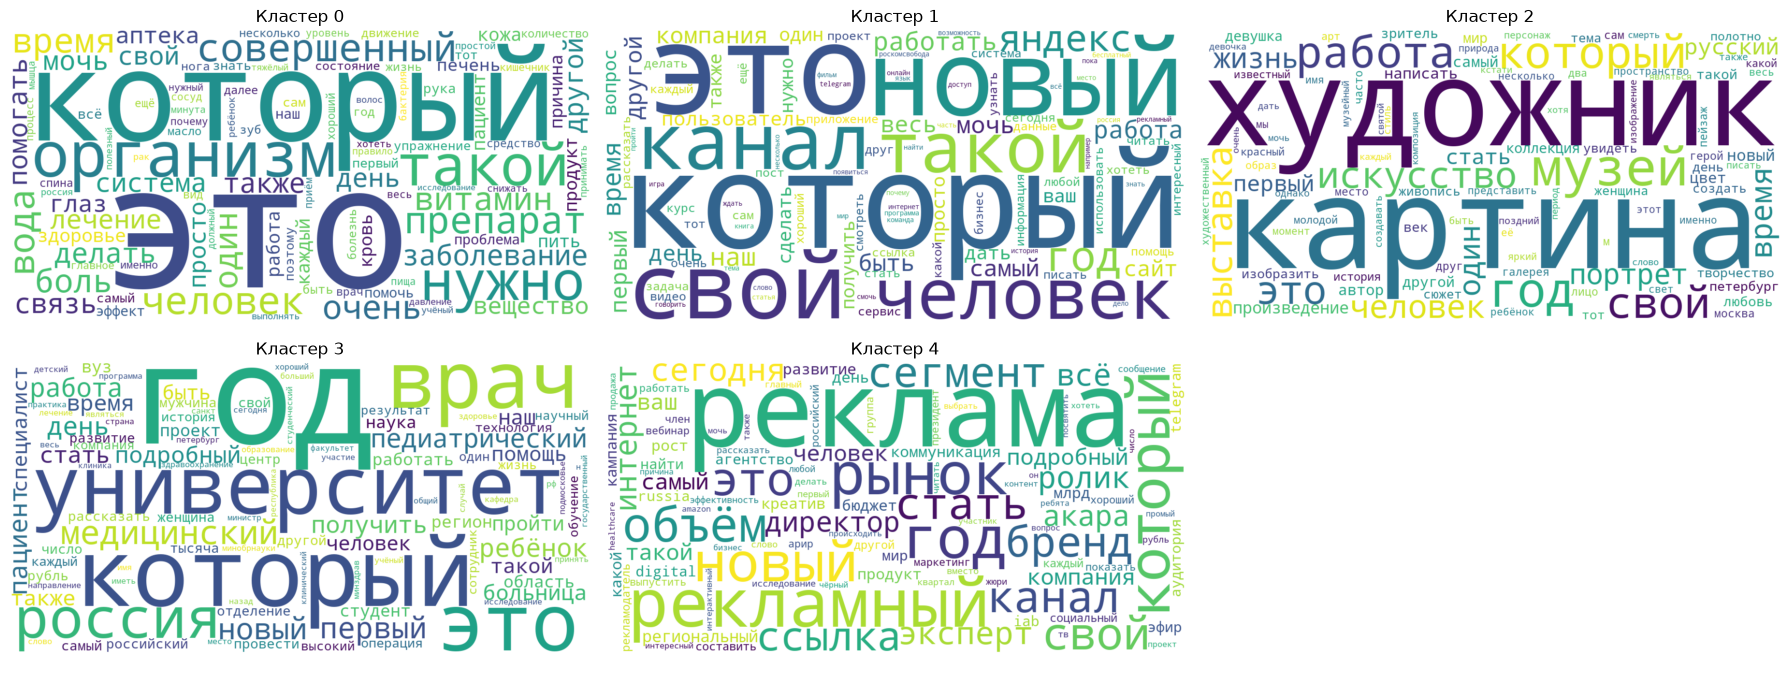

In [97]:
fig, axes = plt.subplots(2, 3, figsize=(18, 7))

for i, ax in enumerate(axes.flatten()[:5]):
    cluster_text = " ".join(text.loc[km == i, "lemmatized_text"])
    wordcloud = WordCloud(width=1200, height=600, background_color="white", max_words=100, collocations=False).generate(cluster_text)

    ax.imshow(wordcloud, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"Кластер {i}")

axes.flatten()[5].axis("off")

plt.tight_layout()
plt.show()

# __11.__ Задание со звездочкой. Оберни всю работу выше в итоговый пайплайн следующего вида:  

   * `MyCustomPreprocessorText` __->__ `CountVectorizer` __->__ `TruncatedSVD` __->__ `Kmeans`
   * `MyCustomPreprocessorText` внутри себя будет содержать все этапы предобработки и очистки текста:
        - `clean` __->__ `remove_stopwords` __->__ `lemmitize`
   * Обучи и подай на вход текст "Этот текст о рекламе, о маркетинге и его пользе для любого продукта для людей" и проверь, к какому кластеру отнесется данный объект

__Некоторый шаблон в помощи сборки своего препроцессора указан ниже__

In [62]:
from sklearn.base import BaseEstimator, TransformerMixin
import pymorphy3

class MyCustomTextPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.stop_words = self.get_stopwords_list() 
        self.morph = pymorphy3.MorphAnalyzer()

    def fit(self, X, y=None): # Препроцессору обучаться не нужно, его нужно только преобразовывать, поэтому тут пусто      
        return self

    def transform(self, texts, y=None): # Будет преобразоваывать
        return [self.preprocess(text) for text in texts]

    # Здесь можно прописать код получения словаря со стоп-словами
    def get_stopwords_list(self): 
        sw = stopwords.words('russian')
        return sw # stop_words

    # Функция по очистке текста
    def clean(self, text):
        # вставьте сюда свою функцию clean из заданий выше
        text = text.lower() # нижний регистр
        text = re.sub(r'http\S+', " ", text) # удаляем ссылки
        text = re.sub(r'@\w+',' ',text) # удаляем упоминания пользователей
        text = re.sub(r'#\w+', ' ', text) # удаляем хэштеги
        text = re.sub(r'\d+', ' ', text) # удаляем числа
        text = re.sub(r'[^а-яёa-z\s]', ' ', text) # удаляем знаки препинания, цифры, эмодзи и специальные символы
        text = re.sub(r'\s+', ' ', text).strip()  # убираем лишние пробелы
        return text # text

    def remove_stopwords(self, text):
        # Здесь можно вставить свою функцию remove_stopwords написанную в заданиях выше
        filtered_text = [
            word for word in text.split()
            if word not in self.stop_words
        ]
        return ' '.join(filtered_text)
    
    def lemmatize(self, text):
        # Вставьте lemmatize
        lemmatized_text = [
            self.morph.parse(word)[0].normal_form
            for word in text.split()
        ]
        return ' '.join(lemmatized_text)

    # Функция, которая запустит последовательный запуск всех этапов выше
    def preprocess(self, text):
        text = self.clean(text)
        text = self.remove_stopwords(text)
        text = self.lemmatize(text)
        return text

* Проверьте его, работает ли правильно transform у этого класса, если все ок 

In [64]:
preprocessor = MyCustomTextPreprocessor()

cleaned_text = preprocessor.transform(text['content'])

print(cleaned_text[:3])

['мужчина метро оскорбить сумка репродукция картина вчера сентябрь православный веровать скорбно праздновать день усекновение глава пророк предтеча креститель господний иоанн день девушка ехать метро сумка шоперо который изобразить картина андреа соларио саломея голова иоанн креститель c надпись мем голова дом забыть православный пассажир расшатать чувство веровать обратиться полиция девушка выход вагон ждать полиция мужчина требовать посадить год пассажирка случиться нервный срыв судить новость полицейский фрустрированный ситуация пока мужчина заявление написать требовать наказать богохульница', 'один кинотеатр нидерланды просмотр новый часть ужастик крик сначала нужно громко покричать экран вывести шкала оценить уровень громкость крик отрепетировать смотреть фильм', 'христос галилейский море эжен делакруакартина посвятить сюжет описать три евангелие новый завет плыть море иисус свой ученик демонстрировать сила христианский вера вызвать буря шквальный ветер живописец настолько захвати

* А теперь соберите полный пайплайн и посчитайте кластер данного текста

In [69]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

In [71]:
pipeline = Pipeline([
    ('preprocessor', MyCustomTextPreprocessor()),
    ('vectorizer', CountVectorizer()),
    ('svd', TruncatedSVD(n_components=100, random_state=42)),
    ('kmeans', KMeans(n_clusters=5, random_state=42))
])

In [72]:
pipeline.fit(text['content'])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('vectorizer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


In [73]:
clusters = pipeline.predict(text['content'])

text['cluster'] = clusters

print(text[['content', 'label', 'cluster']].head())

                                             content       label  cluster
0  Мужчину в метро оскорбила сумка с репродукцией...   искусство        2
1  В одном из кинотеатров Нидерландов перед просм...   маркетинг        3
2  🖼️ «Христос в Галилейском море» — Эжен Делакру...   искусство        2
3  24 года Яндекс работает, чтобы делать жизнь уд...  технологии        3
4  Телеком 2022 - 2 прибыльных #MVNO и остальные🔥...  технологии        3


In [74]:
cluster = pipeline.predict([text['content'].iloc[0]])

print(f'Текст относится к кластеру: {cluster[0]}')

Текст относится к кластеру: 2
